# Untuk inferensi demo

In [1]:
import importlib.util
import subprocess
import sys
# Tidak mengganti PyTorch bawaan Kaggle.
for module, package in [('ultralytics', 'ultralytics==8.4.215'), ('ipywidgets', 'ipywidgets')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])
import gc, io, json, time, zipfile, hashlib
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageOps, ImageDraw, ImageFont
from IPython.display import display
from ultralytics import YOLO
from torchvision.models.detection import maskrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
from torchvision.transforms.functional import to_tensor
import ipywidgets as widgets
DEMO_OUT = Path('/kaggle/working/demo_langsung_041')
DEMO_OUT.mkdir(parents=True, exist_ok=True)
DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'
print('Perangkat:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU; aktifkan GPU agar demo lebih cepat')
RUN_NAMES = [f'{model}_{size}_resmi' for model in ['yolov8n_seg', 'yolov8s_seg', 'maskrcnn_r50_fpn'] for size in [320, 640, 960]]
# Isi hanya jika tersedia beberapa salinan checkpoint dari run yang sama.
CHECKPOINT_PATHS = {}
# CHECKPOINT_PATHS['yolov8s_seg_640_resmi'] = '/kaggle/input/.../best.pt'


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Perangkat: Tesla T4


In [2]:
def checkpoint_path(run):
    filename = 'best.pth' if run.startswith('maskrcnn') else 'best.pt'
    if run in CHECKPOINT_PATHS:
        path = Path(CHECKPOINT_PATHS[run])
        if not path.is_file():
            raise FileNotFoundError(path)
        return path
    bases = [Path('/kaggle/input'), Path('/kaggle/working/visi_komputer_041')]
    direct = sorted({p for base in bases for p in base.glob(f'**/{filename}') if run in p.parts})
    if len(direct) == 1:
        return direct[0]
    if len(direct) > 1:
        raise ValueError(f'Ada beberapa checkpoint {run}. Isi CHECKPOINT_PATHS dengan satu path yang dipilih: {direct}')
    archives = sorted({p for base in bases for p in base.glob(f'**/{run}.zip')})
    if len(archives) != 1:
        raise FileNotFoundError(f'Tambahkan output training melalui Add Input. Ditemukan {len(archives)} ZIP untuk {run}.')
    target = DEMO_OUT / 'checkpoints' / run / filename
    if not target.exists():
        with zipfile.ZipFile(archives[0]) as z:
            members = [m for m in z.namelist() if not m.startswith('__MACOSX/') and Path(m).name == filename]
            if len(members) != 1:
                raise ValueError(f'Checkpoint tidak tunggal dalam {archives[0].name}: {members}')
            target.parent.mkdir(parents=True, exist_ok=True)
            with z.open(members[0]) as source, target.open('wb') as dest:
                import shutil
                shutil.copyfileobj(source, dest)
    return target

_cached_model = None
_cached_run = None
_cached_names = None

def get_demo_model(run):
    global _cached_model, _cached_run, _cached_names
    if run not in RUN_NAMES:
        raise ValueError(f'Nama model tidak dikenal: {run}')
    if _cached_run == run:
        return _cached_model, _cached_names
    _cached_model = None
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    path = checkpoint_path(run)
    size = int(run.split('_')[-2])
    if run.startswith('yolo'):
        model = YOLO(str(path))
        names = [model.names[i] for i in range(len(model.names))]
    else:
        # Checkpoint berasal dari notebook training sendiri.
        state = torch.load(path, map_location='cpu', weights_only=False)
        names = state['names']
        if state['config']['input_size'] != size:
            raise ValueError('Ukuran checkpoint tidak sesuai nama run.')
        model = maskrcnn_resnet50_fpn(weights=None, weights_backbone=None,
            min_size=size, max_size=size, box_score_thresh=0.001, box_detections_per_img=100)
        features = model.roi_heads.box_predictor.cls_score.in_features
        model.roi_heads.box_predictor = FastRCNNPredictor(features, len(names) + 1)
        features = model.roi_heads.mask_predictor.conv5_mask.in_channels
        model.roi_heads.mask_predictor = MaskRCNNPredictor(features, 256, len(names) + 1)
        model.load_state_dict(state['model'])
        model.to(DEVICE).eval()
        del state
    _cached_model, _cached_run, _cached_names = model, run, names
    print('Checkpoint dimuat:', path)
    return model, names


def read_demo_photo(upload_value, photo_path):
    if photo_path.strip():
        path = Path(photo_path)
        if not path.is_file():
            raise FileNotFoundError(path)
        blob, filename = path.read_bytes(), path.name
    elif upload_value:
        if isinstance(upload_value, dict):  # ipywidgets 7
            filename, entry = next(iter(upload_value.items()))
        else:  # ipywidgets 8
            entry = upload_value[0]
            filename = entry['name']
        blob = bytes(entry['content'])
    else:
        raise ValueError('Unggah foto JPG/PNG pada Upload foto atau isi PHOTO_PATH.')
    with Image.open(io.BytesIO(blob)) as source:
        photo = ImageOps.exif_transpose(source).convert('RGB')
    return photo, filename, hashlib.sha256(blob).hexdigest()


@torch.inference_mode()
def predict_demo(photo, model, names, run, confidence):
    if not 0.001 <= confidence <= 1:
        raise ValueError('Confidence harus antara 0,001 dan 1.')
    size = int(run.split('_')[-2])
    view = photo.copy()
    view.thumbnail((1400, 1400))
    overlay = view.convert('RGBA')
    rows = []
    palette = [(230,80,55),(40,150,220),(65,180,95),(170,90,200),(230,170,45),(30,185,180)]
    def paint(mask, label, score, color):
        nonlocal overlay
        if not mask.getbbox():
            return
        alpha = mask.point(lambda v: round(v * 0.35))
        layer = Image.new('RGBA', view.size, (*color, 0))
        layer.putalpha(alpha)
        overlay = Image.alpha_composite(overlay, layer)
        box = mask.getbbox()
        draw = ImageDraw.Draw(overlay)
        draw.rectangle(box, outline=(*color,255), width=2)
        text = f'{label} {score:.2f}'
        try:
            font = ImageFont.truetype('DejaVuSans.ttf', 17)
        except OSError:
            font = ImageFont.load_default()
        x,y = box[0],max(0,box[1]-23)
        text_box = draw.textbbox((x,y),text,font=font)
        draw.rectangle(text_box, fill=(255,255,255,230))
        draw.text((x,y),text,fill=(0,0,0,255),font=font)
    started = time.perf_counter()
    if run.startswith('yolo'):
        result = model.predict(photo, imgsz=size, conf=confidence, iou=0.7,
            max_det=100, device=DEVICE, retina_masks=False, verbose=False)[0]
        if result.masks is not None:
            for i,(box,poly) in enumerate(zip(result.boxes,result.masks.xy)):
                if len(poly) < 3:
                    continue
                label, score = names[int(box.cls.item())],float(box.conf.item())
                mask = Image.new('L',view.size,0)
                points = [(float(x)*view.width/photo.width,float(y)*view.height/photo.height) for x,y in poly]
                ImageDraw.Draw(mask).polygon(points,fill=255)
                rows.append({'kelas':label,'confidence':score})
                paint(mask,label,score,palette[i%len(palette)])
        del result
    else:
        scale = size/max(photo.size)
        small = photo.resize((max(1,round(photo.width*scale)),max(1,round(photo.height*scale))),Image.Resampling.BILINEAR)
        output = model([to_tensor(small).to(DEVICE)])[0]
        for i,(label,score,prob) in enumerate(zip(output['labels'],output['scores'],output['masks'])):
            score = float(score.item())
            if score < confidence:
                continue
            label = names[int(label.item())-1]
            mask = Image.fromarray(prob[0].cpu().numpy()).resize(view.size,Image.Resampling.BILINEAR)
            mask = Image.fromarray((np.asarray(mask) >= 0.5).astype(np.uint8) * 255)
            if not mask.getbbox():
                continue
            rows.append({'kelas':label,'confidence':score})
            paint(mask,label,score,palette[i%len(palette)])
        del output
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return view, overlay.convert('RGB'), pd.DataFrame(rows,columns=['kelas','confidence']), time.perf_counter()-started


## Unggah foto baru
Jalankan sel ini sekali, lalu klik **Upload foto**. Pilih JPG atau PNG. Foto boleh diambil saat demo dan dipindahkan dari HP ke laptop.

Jika tombol tidak muncul, gunakan Upload pada panel Input Kaggle, salin path gambar, dan isi `PHOTO_PATH` di sel Pengaturan demo. Path yang terisi akan dipakai lebih dahulu daripada tombol upload.


In [3]:
photo_upload = widgets.FileUpload(accept='.jpg,.jpeg,.png', multiple=False, description='Upload foto')
display(photo_upload)


FileUpload(value=(), accept='.jpg,.jpeg,.png', description='Upload foto')

## Pengaturan demo
Ubah nama model, confidence, atau path foto di sini. Nama konfigurasi tersedia pada `RUN_NAMES`.
Contoh: `yolov8n_seg_640_resmi`, `yolov8s_seg_640_resmi`, `maskrcnn_r50_fpn_960_resmi`.


In [4]:
MODEL_NAME = 'yolov8s_seg_640_resmi'
CONFIDENCE = 0.25
PHOTO_PATH = '/kaggle/input/datasets/sittiaminah/coba02/coba.jpeg' 
print('Model:', MODEL_NAME, '| Confidence:', CONFIDENCE)


Model: yolov8s_seg_640_resmi | Confidence: 0.25


## Prediksi
Jalankan ulang sel ini setelah mengubah pengaturan atau mengunggah foto lain. Jika hanya mengubah confidence, jalankan lagi Pengaturan demo lalu Prediksi. Model yang sama tetap tersimpan dalam memori.

Foto baru belum mempunyai ground truth, sehingga demo menampilkan prediksi, bukan menghitung AP foto baru.


Checkpoint dimuat: /kaggle/input/notebooks/sittiaminah/viskom-train/visi_komputer_041/yolov8s_seg_640_resmi/weights/best.pt


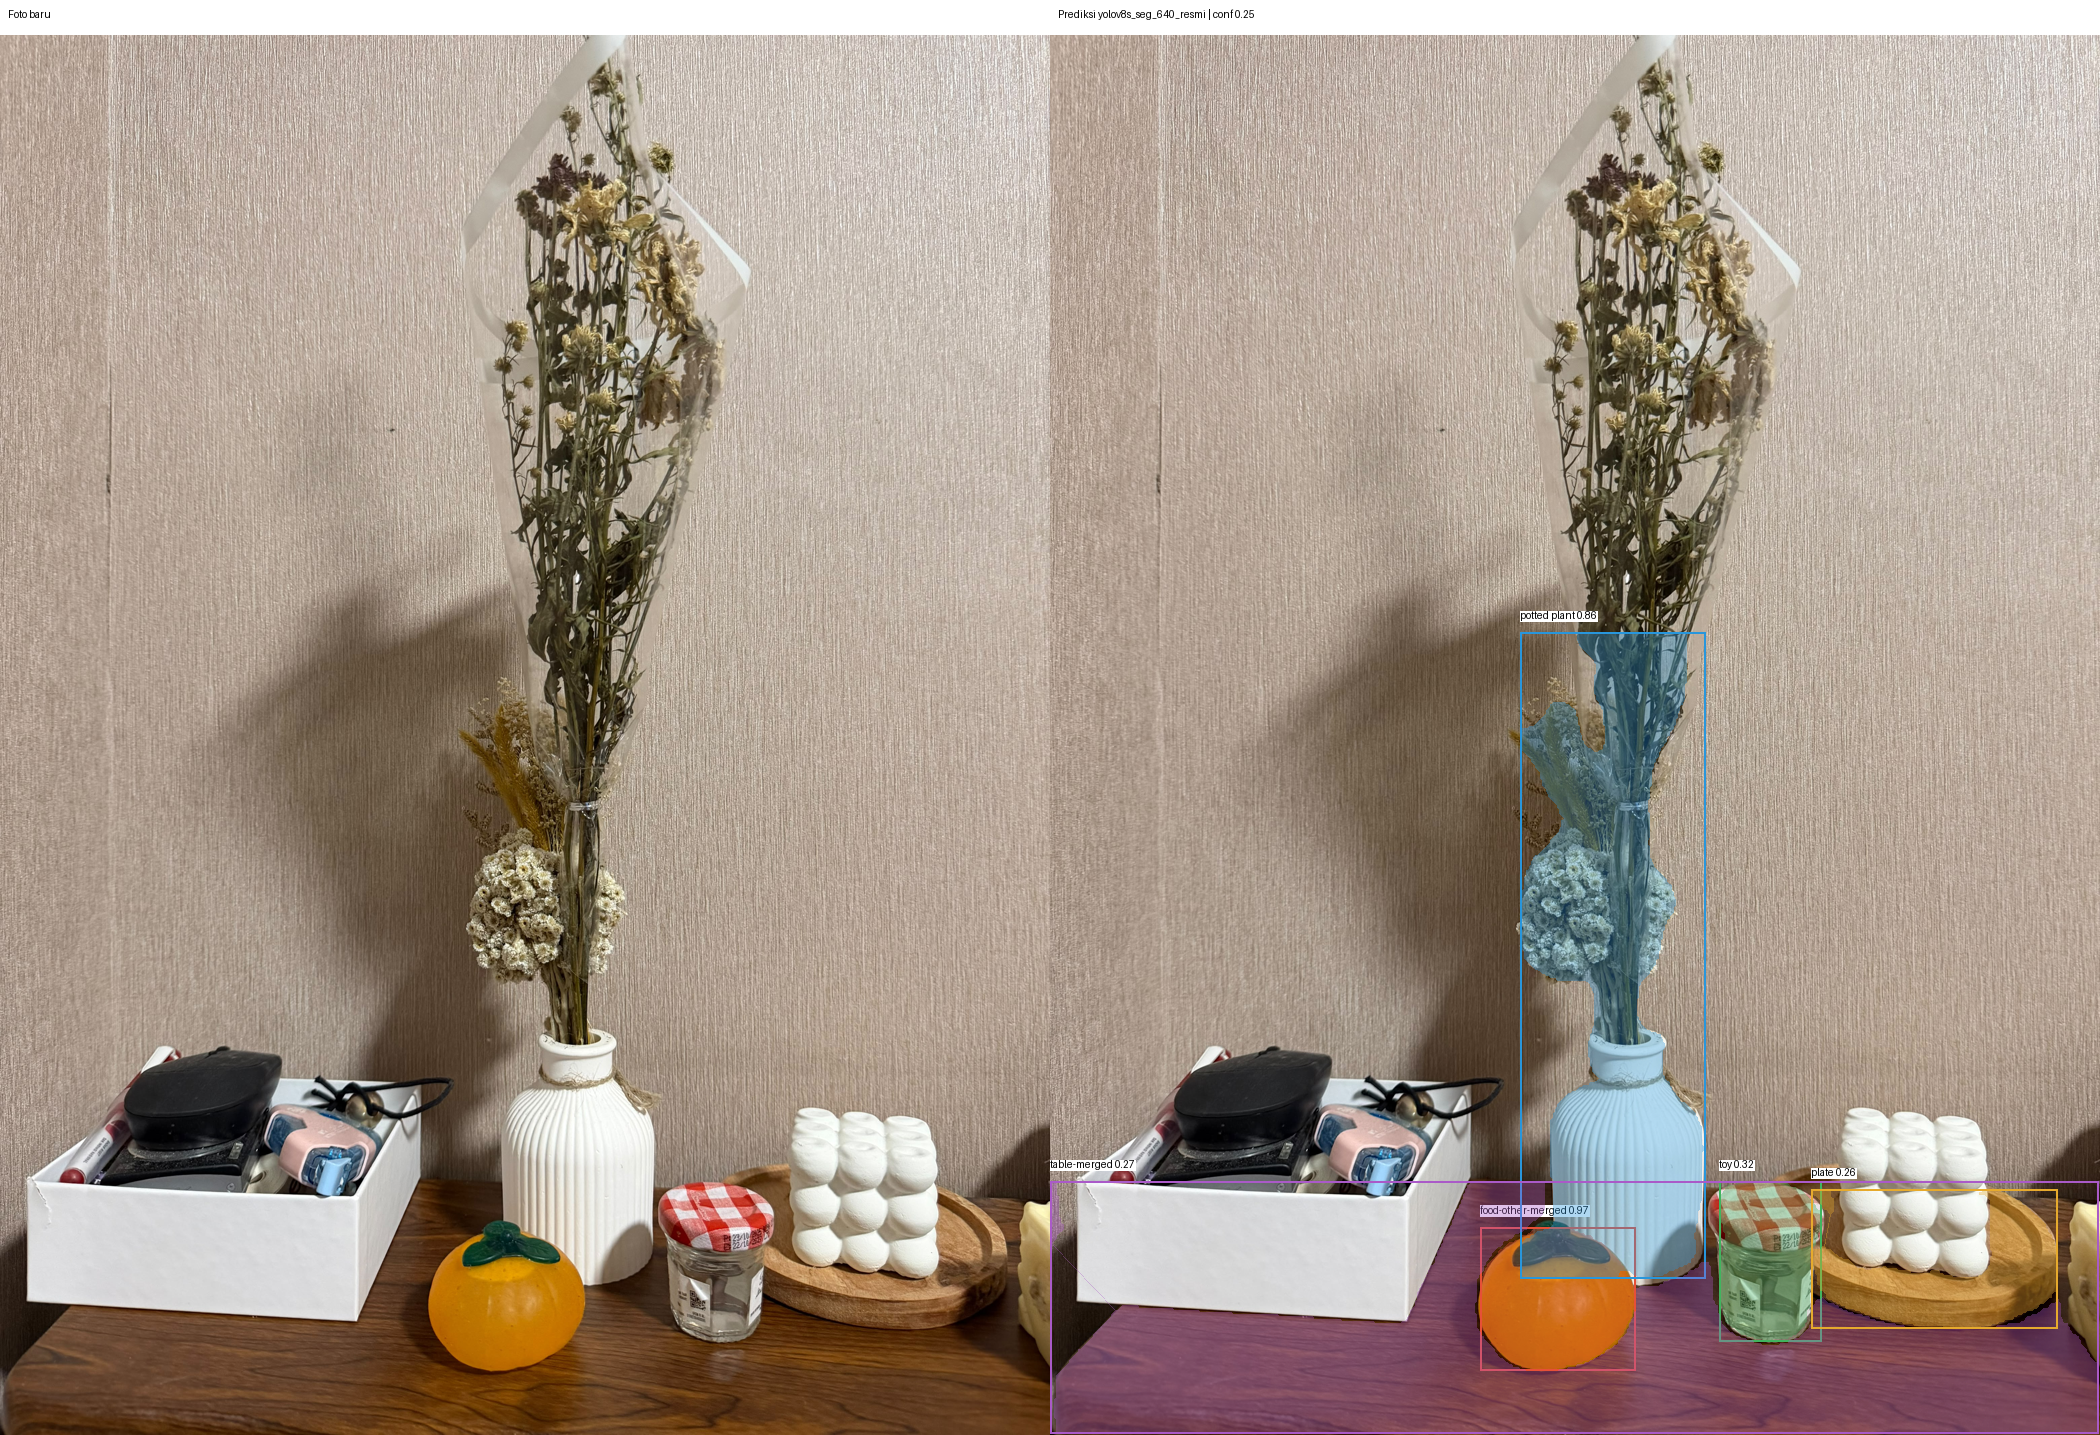

,kelas,confidence
0,food-other-merged,0.973758
1,potted plant,0.862740
2,toy,0.323338
3,table-merged,0.267889
4,plate,0.261053


Jumlah instance: 5
Waktu prediksi dan penggambaran: 6.20 detik (tidak termasuk load checkpoint).
Hasil disimpan di /kaggle/working/demo_langsung_041


In [5]:
demo_photo, demo_filename, demo_photo_hash = read_demo_photo(photo_upload.value, PHOTO_PATH)
demo_model, demo_names = get_demo_model(MODEL_NAME)
original_view, predicted_view, detections, demo_seconds = predict_demo(
    demo_photo, demo_model, demo_names, MODEL_NAME, CONFIDENCE)
combined = Image.new('RGB',(original_view.width*2,original_view.height+35),'white')
combined.paste(original_view,(0,35))
combined.paste(predicted_view,(original_view.width,35))
ImageDraw.Draw(combined).text((8,8),'Foto baru',fill='black')
ImageDraw.Draw(combined).text((original_view.width+8,8),f'Prediksi {MODEL_NAME} | conf {CONFIDENCE}',fill='black')
display(combined)
display(detections)
print('Jumlah instance:',len(detections))
print(f'Waktu prediksi dan penggambaran: {demo_seconds:.2f} detik (tidak termasuk load checkpoint).')
# Hasil setiap percobaan disimpan terpisah sebagai bukti demo.
stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
demo_stem = f'{stamp}_{MODEL_NAME}_conf{CONFIDENCE:.2f}'
combined.save(DEMO_OUT / f'{demo_stem}.jpg',quality=92)
detections.to_csv(DEMO_OUT / f'{demo_stem}.csv',index=False)
(DEMO_OUT / f'{demo_stem}.json').write_text(json.dumps({
    'created_at_utc':stamp,'filename':demo_filename,'photo_sha256':demo_photo_hash,
    'run':MODEL_NAME,'confidence':CONFIDENCE,'instances':len(detections),
    'prediction_and_render_seconds':demo_seconds},indent=2))
print('Hasil disimpan di',DEMO_OUT)

## AP satu kelas dari hasil evaluasi
Bagian ini membaca hasil test set yang sudah dianotasi. Angkanya bukan AP foto baru di atas. Pilih model, split, dan kelas, lalu jalankan sel berikutnya. File hasil evaluasi harus sudah ditambahkan melalui Add Input.


In [6]:
AP_MODEL = 'yolov8s_seg_640_resmi'
AP_TEST_SET = 'sendiri'  # 'sendiri' atau 'resmi'
AP_CLASS = 'book'       # 'chair', 'curtain', 'bed', dll

In [7]:
def read_run_csv(run, relative):
    for base in [Path('/kaggle/working/evaluasi_041'),Path('/kaggle/input')]:
        candidates = [p for p in base.glob(f'**/{Path(relative).name}')
                      if tuple(p.parts[-(len(Path(relative).parts)+1):]) == (run,*Path(relative).parts)]
        if len(candidates)==1:
            return pd.read_csv(candidates[0]),str(candidates[0])
        if len(candidates)>1:
            raise ValueError(f'Ada beberapa salinan CSV {run}/{relative}: {candidates}')
    archives = list(Path('/kaggle/input').glob('**/evaluasi_041_hasil.zip'))
    for archive in archives:
        with zipfile.ZipFile(archive) as z:
            members = [m for m in z.namelist() if not m.startswith('__MACOSX/') and m.endswith(f'{run}/{relative}')]
            if len(members)==1:
                return pd.read_csv(io.BytesIO(z.read(members[0]))),f'{archive.name}:{members[0]}'
    raise FileNotFoundError('Tambahkan hasil evaluasi sebagai Input atau periksa nama file ZIP.')

if AP_TEST_SET not in ['sendiri','resmi']:
    raise ValueError('AP_TEST_SET harus sendiri atau resmi.')
ap_table, ap_source = read_run_csv(AP_MODEL,f'{AP_TEST_SET}/per_class_all.csv')
print('Sumber:',ap_source)
ap_selected = ap_table[ap_table['class'].str.casefold()==AP_CLASS.casefold()].copy()
if ap_selected.empty:
    print('Kelas tidak tersedia pada tabel ini. Kelas yang tersedia:')
    print(', '.join(ap_table['class'].tolist()))
else:
    ap_selected['mask_AP50_95_persen'] = ap_selected['mask_AP50_95']*100
    display(ap_selected)
print('AP dibaca dari evaluasi mask pada ground truth test set, bukan dari satu foto demo.')

Sumber: /kaggle/input/datasets/sittiaminah/hasil-evaluasi/yolov8s_seg_640_resmi/sendiri/per_class_all.csv


,class,mask_AP50_95,mask_AP50_95_persen
2,book,0.007638,0.763791


AP dibaca dari evaluasi mask pada ground truth test set, bukan dari satu foto demo.


## Ambil results csv asli dari output training

In [8]:
csv_evidence = DEMO_OUT / 'bukti_training_asli'
records = []
for run in RUN_NAMES:
    target = csv_evidence / run / 'results.csv'
    candidates = [p for p in Path('/kaggle/input').glob('**/results.csv') if run in p.parts]
    blob, source = None, None
    if len(candidates)==1:
        blob, source = candidates[0].read_bytes(),str(candidates[0])
    elif len(candidates)>1:
        records.append({'run':run,'status':'beberapa salinan; pilih manual','source':str(candidates)})
        continue
    else:
        archives = list(Path('/kaggle/input').glob(f'**/{run}.zip'))
        if len(archives)==1:
            with zipfile.ZipFile(archives[0]) as z:
                members = [m for m in z.namelist() if not m.startswith('__MACOSX/') and Path(m).name=='results.csv']
                if len(members)==1:
                    blob,source = z.read(members[0]),f'{archives[0]}:{members[0]}'
    if blob is not None:
        target.parent.mkdir(parents=True,exist_ok=True)
        target.write_bytes(blob)
        records.append({'run':run,'status':'tersalin','source':source,'sha256':hashlib.sha256(blob).hexdigest()})
    else:
        records.append({'run':run,'status':'belum ditemukan','source':''})
csv_evidence.mkdir(parents=True,exist_ok=True)
pd.DataFrame(records).to_csv(csv_evidence/'sumber_log.csv',index=False)
display(pd.DataFrame(records))
print('Bukti:',csv_evidence)

,run,status,source,sha256
0,yolov8n_seg_320_resmi,tersalin,/kaggle/input/notebooks/sittiaminah/viskom-tra...,267a18ecf3c0e98566b07ad9a436eb18874fe145679d34...
1,yolov8n_seg_640_resmi,tersalin,/kaggle/input/notebooks/sittiaminah/viskom-tra...,0c4294ce3d4bd1d88688543bdf8918b1904ec733b5d55e...
2,yolov8n_seg_960_resmi,tersalin,/kaggle/input/notebooks/sittiaminah/viskom-tra...,59f43c580fc79749d8990e9aad6bdb07bdfcb8401f446d...
3,yolov8s_seg_320_resmi,tersalin,/kaggle/input/notebooks/sittiaminah/viskom-tra...,a8e3e193da32354a79238b72f6115ca82a4e5c232ab4ea...
4,yolov8s_seg_640_resmi,tersalin,/kaggle/input/notebooks/sittiaminah/viskom-tra...,ce6931b48464d5591afaf6241235114b7d9e78497d7920...
5,yolov8s_seg_960_resmi,tersalin,/kaggle/input/notebooks/sittiaminah/viskom-tra...,e5919f3c3e339c0559ad05461580c7356a5435ffc11bbd...
6,maskrcnn_r50_fpn_320_resmi,tersalin,/kaggle/input/notebooks/sittiaminah/viskom-tra...,d77c8172efbaaa3ac4917355460f3efcd521d61f97ca20...
7,maskrcnn_r50_fpn_640_resmi,tersalin,/kaggle/input/notebooks/sittiaminah/viskom-tra...,56016f31954629f07f3a41e5e78eb3c9a5a8d348fd6476...
8,maskrcnn_r50_fpn_960_resmi,tersalin,/kaggle/input/notebooks/sittiaminah/viskom-tra...,750b729e55b60e0e4e5394c0ba8bc66a46a2c3518e30d5...


Bukti: /kaggle/working/demo_langsung_041/bukti_training_asli
